In [76]:
!pip install -q tensorflow matplotlib seaborn scikit-learn pandas

In [77]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from tensorflow.keras.preprocessing import image
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0, ResNet50, MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [78]:
uploaded = files.upload()

Saving dataset-resized.zip to dataset-resized (1).zip


In [79]:
import zipfile
import os

zip_path = next(iter(uploaded.keys()))

extract_path = "/content/waste_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [80]:
expected_classes = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

dataset_path = None

for root, dirs, files_list in os.walk(extract_path):
    if all(cls in dirs for cls in expected_classes):
        dataset_path = root
        break

if dataset_path is None:
    raise Exception("Could not find all six class folders. Check the extracted dataset.")

print("Dataset folder:", dataset_path)
print("Classes:", os.listdir(dataset_path))

Dataset folder: /content/waste_dataset/dataset-resized
Classes: ['metal', '.DS_Store', 'trash', 'glass', 'paper', 'cardboard', 'plastic']


In [81]:
for cls in expected_classes:
    folder = os.path.join(dataset_path, cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    print(cls, ":", count, "images")

cardboard : 403 images
glass : 501 images
metal : 410 images
paper : 594 images
plastic : 482 images
trash : 137 images


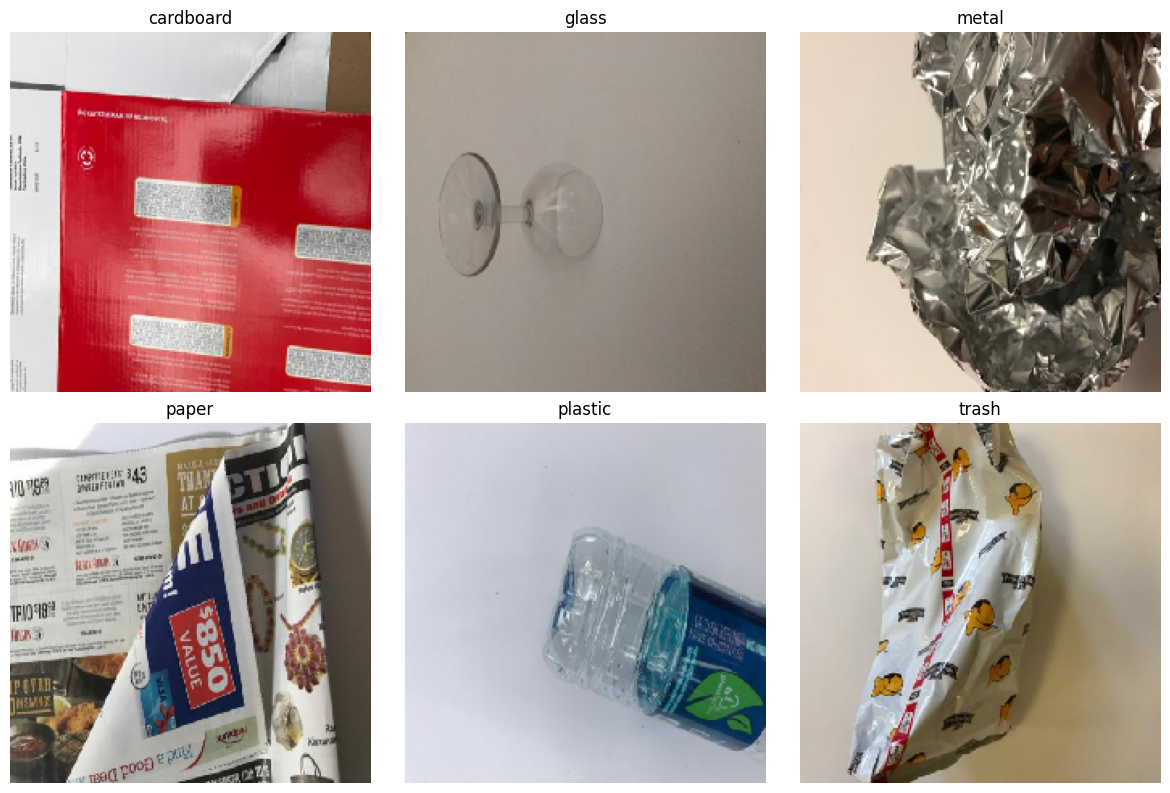

In [82]:
plt.figure(figsize=(12, 8))

for i, cls in enumerate(expected_classes):
    folder = os.path.join(dataset_path, cls)

    img_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    img_path = os.path.join(folder, img_files[0])

    img = image.load_img(img_path, target_size=(224, 224))

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [83]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Class Names:", class_names)
print("Number of Classes:", num_classes)

Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.
Class Names: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of Classes: 6


In [84]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [85]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Total classes:", num_classes)

Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Total classes: 6


In [86]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(np.unique(train_labels), weights)
}

print("Class Weights:", class_weights)

Class Weights: {0: 1.0089820359281436, 1: 0.8446115288220551, 2: 1.046583850931677, 3: 0.7154989384288747, 4: 0.8575063613231552, 5: 3.2718446601941746}


In [87]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.RandomTranslation(0.1, 0.1)
])

In [88]:
def create_model(model_name):

    inputs = layers.Input(shape=(224, 224, 3))

    x = data_augmentation(inputs)

    if model_name == "EfficientNetB0":

        base_model = EfficientNetB0(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )

    elif model_name == "ResNet50":

        base_model = ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )

        x = layers.Lambda(resnet_preprocess)(x)

    elif model_name == "MobileNetV2":

        base_model = MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(224, 224, 3)
        )

        x = layers.Lambda(mobilenet_preprocess)(x)

    base_model.trainable = False

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model, base_model

In [89]:
def get_callbacks(model_name):

    return [
        tf.keras.callbacks.ModelCheckpoint(
            model_name + "_best.keras",
            monitor="val_accuracy",
            save_best_only=True,
            mode="max"
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7
        )
    ]

In [90]:
efficientnet_model, efficientnet_base = create_model("EfficientNetB0")

history_eff_1 = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=get_callbacks("EfficientNetB0")
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 153ms/step - accuracy: 0.6286 - loss: 1.1301 - val_accuracy: 0.8000 - val_loss: 0.6672 - learning_rate: 5.0000e-04
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 138ms/step - accuracy: 0.8046 - loss: 0.5593 - val_accuracy: 0.8396 - val_loss: 0.4833 - learning_rate: 5.0000e-04
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 136ms/step - accuracy: 0.8368 - loss: 0.4440 - val_accuracy: 0.8455 - val_loss: 0.4279 - learning_rate: 5.0000e-04
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 101ms/step - accuracy: 0.8576 - loss: 0.3840 - val_accuracy: 0.8416 - val_loss: 0.3918 - learning_rate: 5.0000e-04
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 8s 118ms/step - accuracy: 0.8867 - loss: 0.3205 - val_accuracy: 0.8554 - val_loss: 0.3834 - learning_rate: 5.0000e-04
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 117ms/step - accuracy: 0.8922 - loss: 0.2905 - val_accuracy: 0.8653 - val_loss: 0.3853 - learning_rate: 5.0000e-04
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 112ms/step - accuracy

In [91]:
efficientnet_base.trainable = True

for layer in efficientnet_base.layers[:-30]:
    layer.trainable = False

for layer in efficientnet_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_eff_2 = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=get_callbacks("EfficientNetB0")
)

Epoch 1/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 23s 176ms/step - accuracy: 0.9179 - loss: 0.2179 - val_accuracy: 0.8812 - val_loss: 0.3499 - learning_rate: 1.0000e-05
Epoch 2/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step - accuracy: 0.9169 - loss: 0.2130 - val_accuracy: 0.8812 - val_loss: 0.3448 - learning_rate: 1.0000e-05
Epoch 3/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 0.9194 - loss: 0.1974 - val_accuracy: 0.8812 - val_loss: 0.3416 - learning_rate: 1.0000e-05
Epoch 4/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.9263 - loss: 0.2007 - val_accuracy: 0.8812 - val_loss: 0.3384 - learning_rate: 1.0000e-05
Epoch 5/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 11s 133ms/step - accuracy: 0.9253 - loss: 0.1951 - val_accuracy: 0.8851 - val_loss: 0.3364 - learning_rate: 1.0000e-05
Epoch 6/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - accuracy: 0.9362 - loss: 0.1899 - val_accuracy: 0.8851 - val_loss: 0.3336 - learning_rate: 1.0000e-05
Epoch 7/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 135ms/step - accurac

In [92]:
resnet_model, resnet_base = create_model("ResNet50")

history_res_1 = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=get_callbacks("ResNet50")
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 22s 229ms/step - accuracy: 0.6479 - loss: 1.1167 - val_accuracy: 0.7980 - val_loss: 0.5966 - learning_rate: 5.0000e-04
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 193ms/step - accuracy: 0.8220 - loss: 0.5110 - val_accuracy: 0.8376 - val_loss: 0.4642 - learning_rate: 5.0000e-04
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 11s 179ms/step - accuracy: 0.8501 - loss: 0.4186 - val_accuracy: 0.8376 - val_loss: 0.4580 - learning_rate: 5.0000e-04
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 194ms/step - accuracy: 0.8798 - loss: 0.3356 - val_accuracy: 0.8554 - val_loss: 0.4314 - learning_rate: 5.0000e-04
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 188ms/step - accuracy: 0.8912 - loss: 0.2884 - val_accuracy: 0.8614 - val_loss: 0.4514 - learning_rate: 5.0000e-04
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 187ms/step - accuracy: 0.9016 - loss: 0.2513 - val_accuracy: 0.8713 - val_loss: 0.4458 - learning_rate: 5.0000e-04
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 11s 173ms/step - acc

In [75]:
resnet_base.trainable = True

for layer in resnet_base.layers[:-30]:
    layer.trainable = False

for layer in resnet_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_res_2 = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=get_callbacks("ResNet50")
)

Epoch 1/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 34s 357ms/step - accuracy: 0.8947 - loss: 0.3041 - val_accuracy: 0.8812 - val_loss: 0.4350 - learning_rate: 1.0000e-05
Epoch 2/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 16s 250ms/step - accuracy: 0.9105 - loss: 0.2551 - val_accuracy: 0.8931 - val_loss: 0.4205 - learning_rate: 1.0000e-05
Epoch 3/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 216ms/step - accuracy: 0.9135 - loss: 0.2425 - val_accuracy: 0.8871 - val_loss: 0.4153 - learning_rate: 1.0000e-05
Epoch 4/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 212ms/step - accuracy: 0.9238 - loss: 0.2098 - val_accuracy: 0.8871 - val_loss: 0.4302 - learning_rate: 1.0000e-05
Epoch 5/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 19s 304ms/step - accuracy: 0.9278 - loss: 0.1948 - val_accuracy: 0.8950 - val_loss: 0.3833 - learning_rate: 1.0000e-05
Epoch 6/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 13s 209ms/step - accuracy: 0.9318 - loss: 0.1826 - val_accuracy: 0.8931 - val_loss: 0.3837 - learning_rate: 1.0000e-05
Epoch 7/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 19s 304ms/step - acc

In [93]:
mobilenet_model, mobilenet_base = create_model("MobileNetV2")

history_mob_1 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=get_callbacks("MobileNetV2")
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 167ms/step - accuracy: 0.5806 - loss: 1.2456 - val_accuracy: 0.7703 - val_loss: 0.6758 - learning_rate: 5.0000e-04
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - accuracy: 0.7517 - loss: 0.7090 - val_accuracy: 0.8218 - val_loss: 0.5356 - learning_rate: 5.0000e-04
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - accuracy: 0.7987 - loss: 0.6153 - val_accuracy: 0.8337 - val_loss: 0.5233 - learning_rate: 5.0000e-04
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 96ms/step - accuracy: 0.8121 - loss: 0.4979 - val_accuracy: 0.8356 - val_loss: 0.5046 - learning_rate: 5.0000e-04
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 6s 91ms/step - accuracy: 0.8244 - loss: 0.4720 - val_accuracy: 0.8396 - val_loss: 0.4971 - learning_rate: 5.0000e-04
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - accuracy: 0.8477 - loss: 0.4229 - val_accuracy: 0.8594 - val_loss: 0.4887 - learning_rate: 5.0000e-04
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 82ms/step - accuracy: 0.8

In [94]:
mobilenet_base.trainable = True

for layer in mobilenet_base.layers[:-30]:
    layer.trainable = False

for layer in mobilenet_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_mob_2 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=get_callbacks("MobileNetV2")
)

Epoch 1/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 132ms/step - accuracy: 0.9060 - loss: 0.2582 - val_accuracy: 0.8693 - val_loss: 0.4726 - learning_rate: 1.0000e-05
Epoch 2/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.9011 - loss: 0.2765 - val_accuracy: 0.8673 - val_loss: 0.4749 - learning_rate: 1.0000e-05
Epoch 3/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - accuracy: 0.8927 - loss: 0.2869 - val_accuracy: 0.8713 - val_loss: 0.4639 - learning_rate: 1.0000e-05
Epoch 4/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 11s 104ms/step - accuracy: 0.8952 - loss: 0.2568 - val_accuracy: 0.8733 - val_loss: 0.4680 - learning_rate: 1.0000e-05
Epoch 5/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.9036 - loss: 0.2572 - val_accuracy: 0.8733 - val_loss: 0.4818 - learning_rate: 1.0000e-05
Epoch 6/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 106ms/step - accuracy: 0.8976 - loss: 0.2408 - val_accuracy: 0.8752 - val_loss: 0.4670 - learning_rate: 2.0000e-06
Epoch 7/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0

In [95]:
model_names = [
    "EfficientNetB0",
    "ResNet50",
    "MobileNetV2"
]

models_list = [
    efficientnet_model,
    resnet_model,
    mobilenet_model
]

accuracies = []

for name, model in zip(model_names, models_list):

    loss, accuracy = model.evaluate(val_ds, verbose=0)

    accuracies.append(accuracy * 100)

    print(name, "Validation Accuracy:", round(accuracy * 100, 2), "%")

EfficientNetB0 Validation Accuracy: 89.11 %
ResNet50 Validation Accuracy: 85.54 %
MobileNetV2 Validation Accuracy: 87.92 %


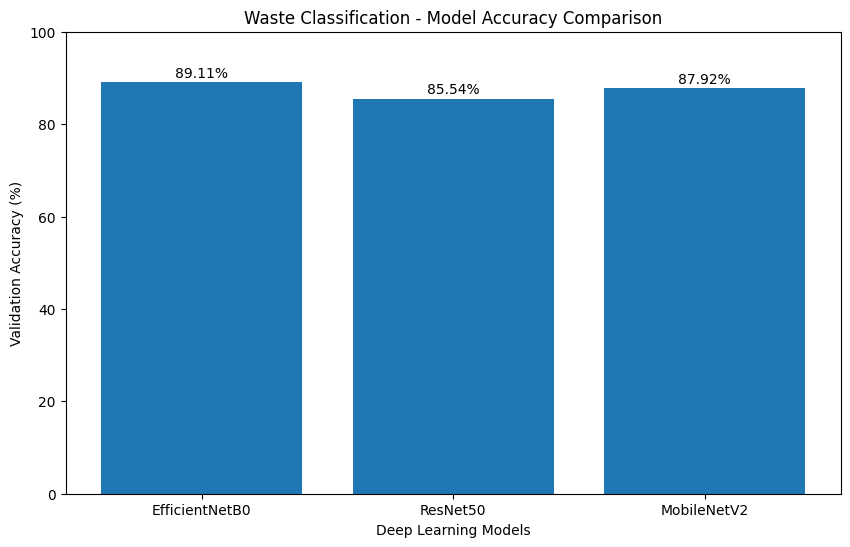

In [96]:
plt.figure(figsize=(10, 6))

bars = plt.bar(model_names, accuracies)

plt.title("Waste Classification - Model Accuracy Comparison")
plt.xlabel("Deep Learning Models")
plt.ylabel("Validation Accuracy (%)")

plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.show()


 EfficientNetB0
              precision    recall  f1-score   support

   cardboard       0.09      0.10      0.10        69
       glass       0.18      0.17      0.17       102
       metal       0.18      0.22      0.20        88
       paper       0.21      0.20      0.20       123
     plastic       0.14      0.13      0.14        89
       trash       0.12      0.12      0.12        34

    accuracy                           0.16       505
   macro avg       0.15      0.16      0.15       505
weighted avg       0.17      0.16      0.16       505



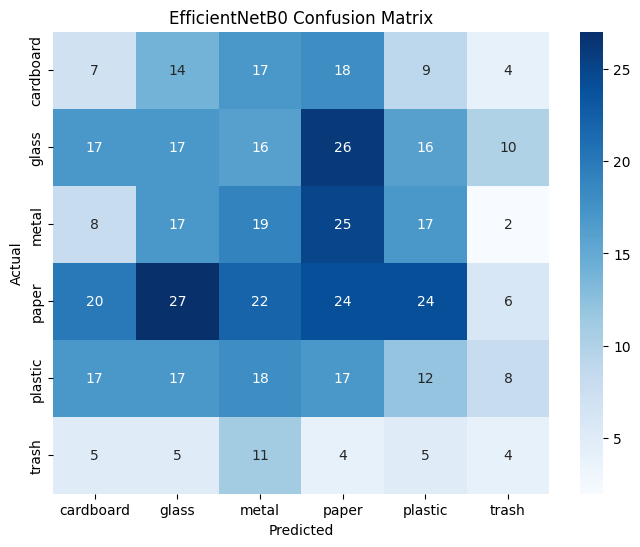


 ResNet50
              precision    recall  f1-score   support

   cardboard       0.14      0.16      0.15        69
       glass       0.20      0.19      0.19       102
       metal       0.12      0.12      0.12        88
       paper       0.19      0.16      0.17       123
     plastic       0.15      0.16      0.15        89
       trash       0.10      0.12      0.11        34

    accuracy                           0.16       505
   macro avg       0.15      0.15      0.15       505
weighted avg       0.16      0.16      0.16       505



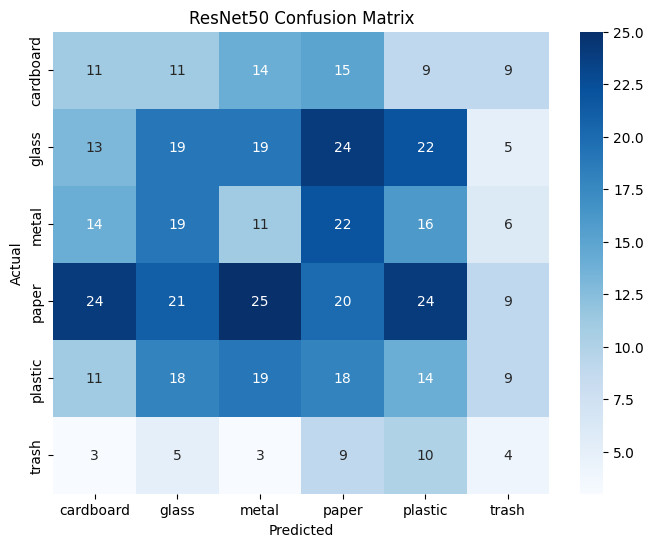


 MobileNetV2
              precision    recall  f1-score   support

   cardboard       0.10      0.10      0.10        69
       glass       0.18      0.18      0.18       102
       metal       0.17      0.18      0.17        88
       paper       0.26      0.25      0.26       123
     plastic       0.14      0.13      0.14        89
       trash       0.11      0.12      0.11        34

    accuracy                           0.17       505
   macro avg       0.16      0.16      0.16       505
weighted avg       0.18      0.17      0.17       505



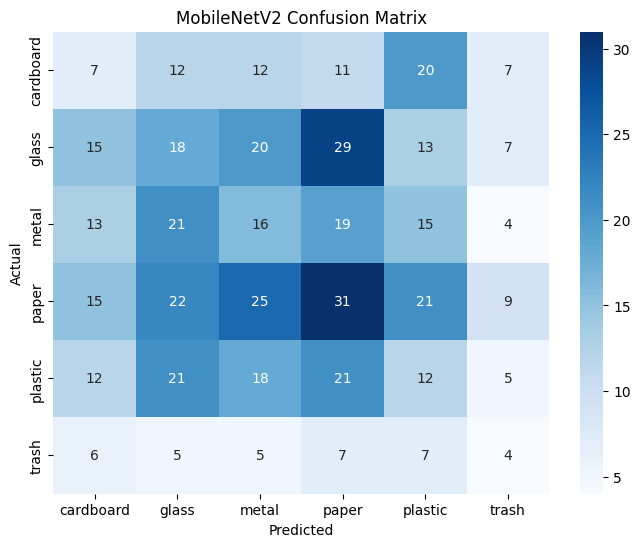

In [97]:
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

for name, model in zip(model_names, models_list):

    predictions = model.predict(val_ds, verbose=0)

    y_pred = np.argmax(predictions, axis=1)

    print("\n", name)
    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

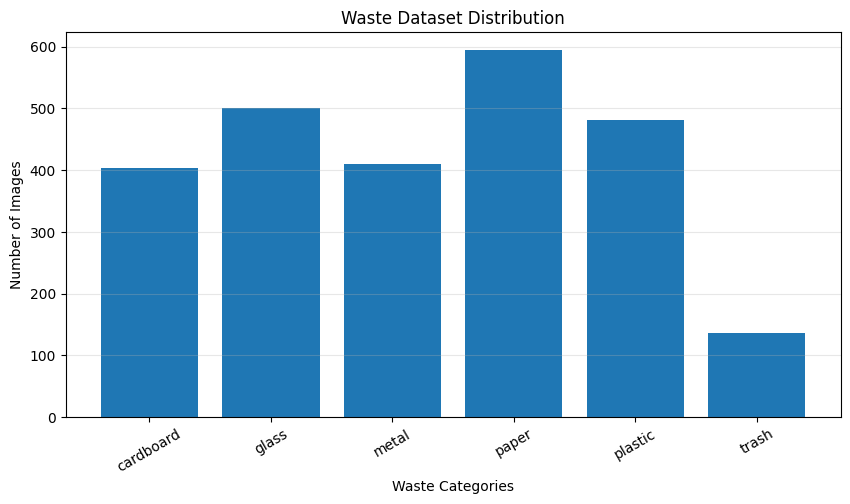

In [99]:
import os
import matplotlib.pyplot as plt

# Compute the image counts for each class
image_counts = {}
for cls in expected_classes:
    folder = os.path.join(dataset_path, cls)
    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])
    image_counts[cls] = count

plt.figure(figsize=(10, 5))
plt.bar(image_counts.keys(), image_counts.values())

plt.title("Waste Dataset Distribution")
plt.xlabel("Waste Categories")
plt.ylabel("Number of Images")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.show()

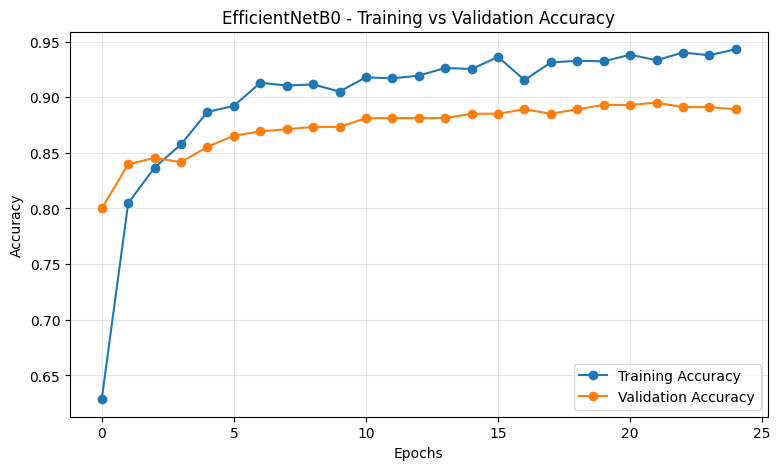

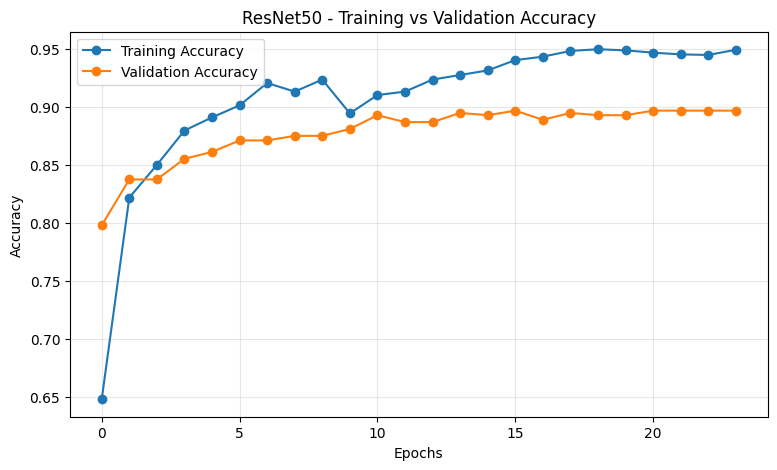

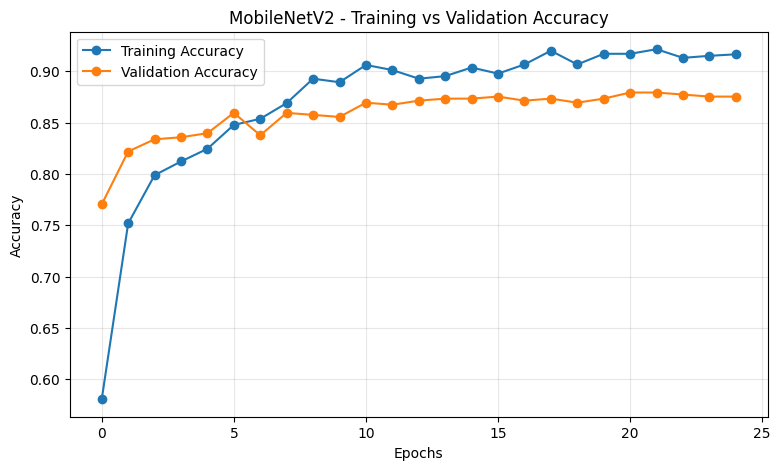

In [101]:
histories = [
    (history_eff_1, history_eff_2),
    (history_res_1, history_res_2),
    (history_mob_1, history_mob_2)
]

for name, (h1, h2) in zip(model_names, histories):

    train_acc = h1.history["accuracy"] + h2.history["accuracy"]
    val_acc = h1.history["val_accuracy"] + h2.history["val_accuracy"]

    plt.figure(figsize=(9, 5))

    plt.plot(train_acc, label="Training Accuracy", marker="o")
    plt.plot(val_acc, label="Validation Accuracy", marker="o")

    plt.title(name + " - Training vs Validation Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

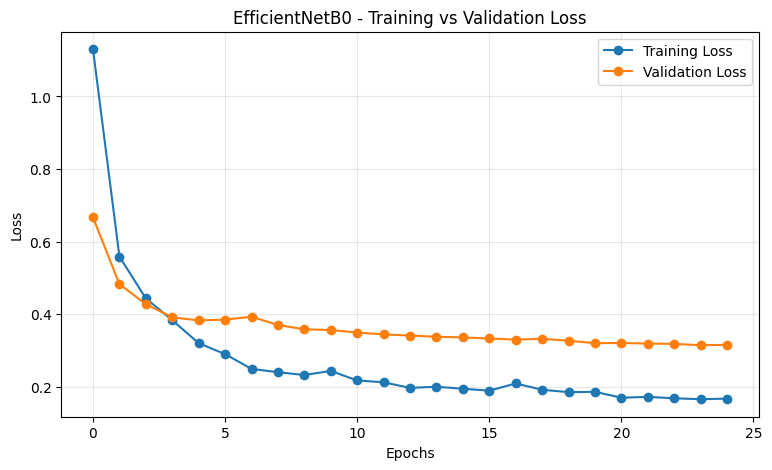

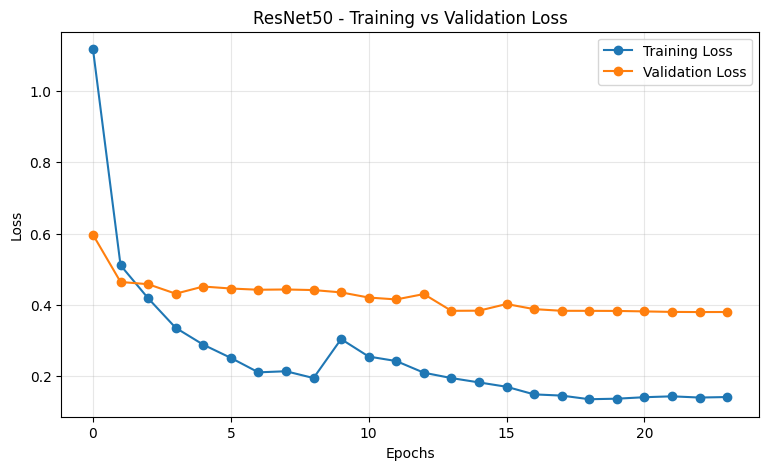

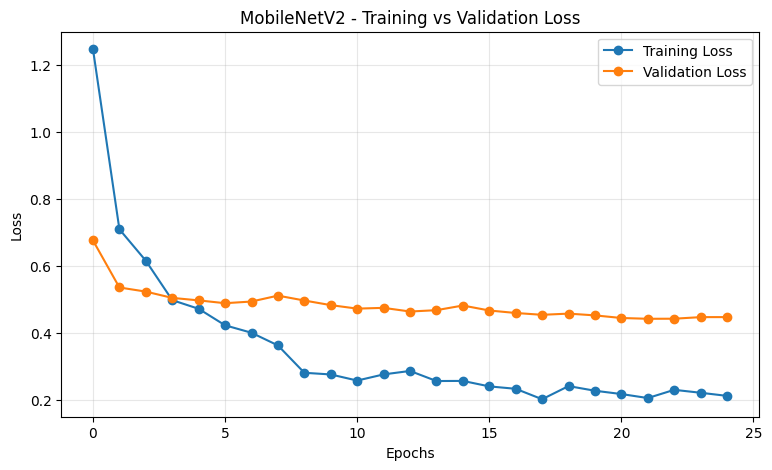

In [102]:
for name, (h1, h2) in zip(model_names, histories):

    train_loss = h1.history["loss"] + h2.history["loss"]
    val_loss = h1.history["val_loss"] + h2.history["val_loss"]

    plt.figure(figsize=(9, 5))

    plt.plot(train_loss, label="Training Loss", marker="o")
    plt.plot(val_loss, label="Validation Loss", marker="o")

    plt.title(name + " - Training vs Validation Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

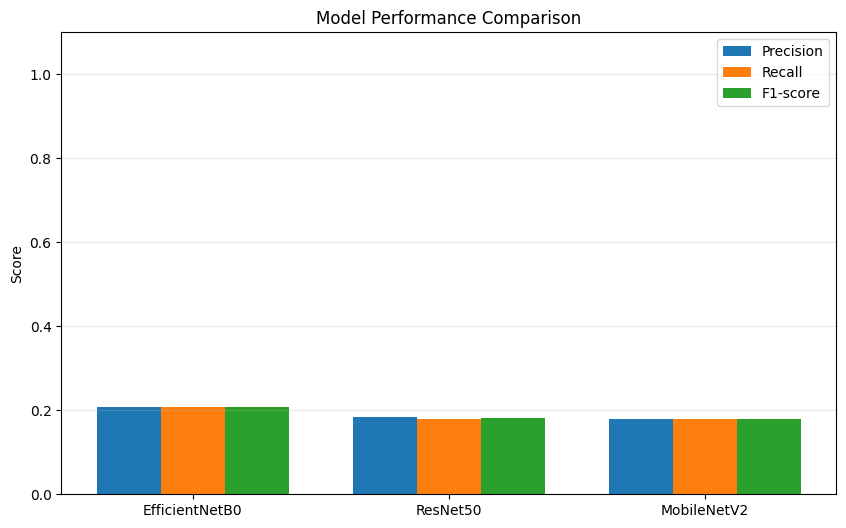

In [103]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_values = []
recall_values = []
f1_values = []

for model in models_list:

    predictions = model.predict(val_ds, verbose=0)
    y_pred = np.argmax(predictions, axis=1)

    precision_values.append(
        precision_score(y_true, y_pred, average="weighted", zero_division=0)
    )

    recall_values.append(
        recall_score(y_true, y_pred, average="weighted", zero_division=0)
    )

    f1_values.append(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    )

x = np.arange(len(model_names))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, precision_values, width, label="Precision")
plt.bar(x, recall_values, width, label="Recall")
plt.bar(x + width, f1_values, width, label="F1-score")

plt.xticks(x, model_names)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

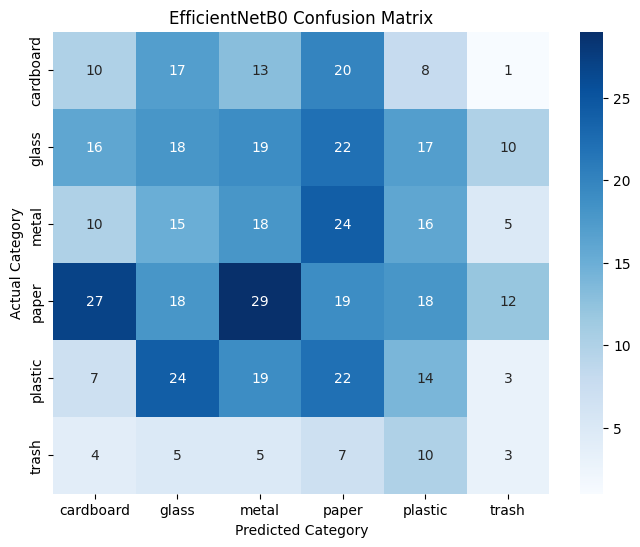

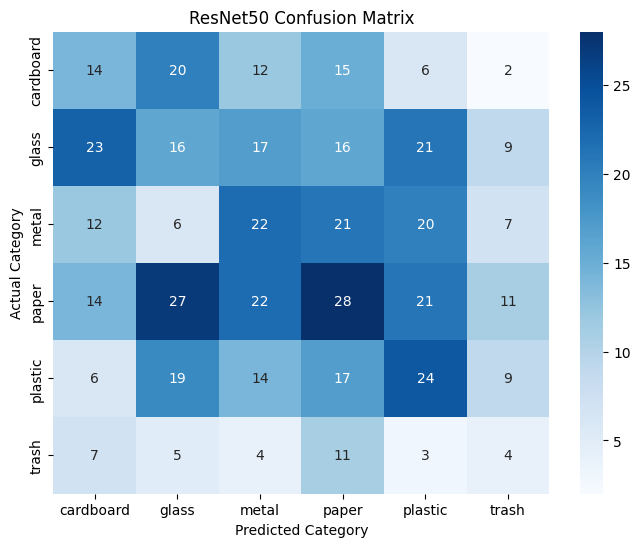

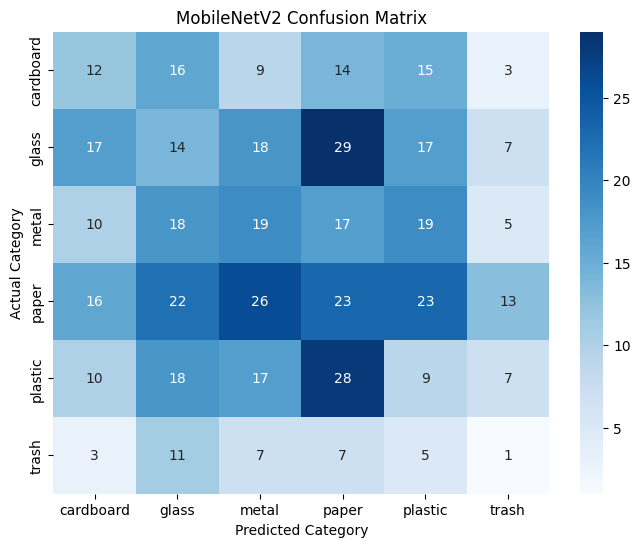

In [104]:
for name, model in zip(model_names, models_list):

    predictions = model.predict(val_ds, verbose=0)
    y_pred = np.argmax(predictions, axis=1)

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted Category")
    plt.ylabel("Actual Category")

    plt.show()

In [105]:
os.makedirs("/content/Waste_Graphs", exist_ok=True)

# Save accuracy comparison
plt.figure(figsize=(10, 6))
plt.bar(model_names, accuracies)
plt.title("Model Accuracy Comparison")
plt.ylabel("Validation Accuracy (%)")
plt.savefig("/content/Waste_Graphs/accuracy_comparison.png")
plt.close()

print("Graphs saved successfully!")

Graphs saved successfully!
